In [10]:
!pip install -q albumentations==1.4.3
!pip install -q pytorch-lightning

import os
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import pytorch_lightning as pl
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torchvision.models import vgg19, VGG19_Weights

In [30]:
class MultiModalDataset(Dataset):
    def __init__(self, sar_dir, opt_cloudy_dir, opt_clear_dir, transform=None):
        self.sar_dir = sar_dir
        self.opt_cloudy_dir = opt_cloudy_dir
        self.opt_clear_dir = opt_clear_dir
        self.transform = transform
        
        # Make it BULLETPROOF: Only keep files that exist in ALL THREE folders!
        sar_files = set(os.listdir(self.sar_dir))
        cloudy_files = set(os.listdir(self.opt_cloudy_dir))
        clear_files = set(os.listdir(self.opt_clear_dir))
        
        # We assume files are named identically across directories
        valid_files = sar_files.intersection(cloudy_files).intersection(clear_files)
        self.files = sorted(list(valid_files))

    def __len__(self):
        return len(self.files)

    def _load_tif(self, path):
        with rasterio.open(path) as src:
            img = src.read()
            img = img.astype(np.float32)
            img = np.nan_to_num(img, nan=0.0, posinf=0.0, neginf=0.0)
            return np.transpose(img, (1, 2, 0)) # (H, W, Channels)

    def __getitem__(self, idx):
        filename = self.files[idx]
        
        # Automatically handle SEN12MS naming conventions (s1 -> s2)
        cloudy_filename = filename.replace("_s1_", "_s2_cloudy_")
        clear_filename = filename.replace("_s1_", "_s2_")
        
        sar_path = os.path.join(self.sar_dir, filename)
        cloudy_path = os.path.join(self.opt_cloudy_dir, cloudy_filename)
        clear_path = os.path.join(self.opt_clear_dir, clear_filename)
        
        sar_img = self._load_tif(sar_path)
        cloudy_img = self._load_tif(cloudy_path)
        clear_img = self._load_tif(clear_path)
        
        # ========================================================
        # THE FIX: Handle 3-band vs 4-band mismatches!
        # If the clear image has an extra band (usually an Alpha/Transparency channel), drop it!
        if clear_img.shape[-1] == 4 and cloudy_img.shape[-1] == 3:
            clear_img = clear_img[:, :, :3]
            
        # If Cloudy is 1-band and Clear is > 1 band (e.g. 3 or 4), duplicate the Cloudy band
        if cloudy_img.shape[-1] == 1 and clear_img.shape[-1] > 1:
            cloudy_img = np.repeat(cloudy_img, clear_img.shape[-1], axis=-1)
        # ========================================================
        
        # ========================================================
        # THE DYNAMIC RANGE HIJACK CURE (Median Multiplier)
        # ========================================================
        # We use the median of valid pixels to calculate the perfect max bound.
        # Since clouds rarely cover >50% of the image, the median perfectly represents the ground!
        
        # -- SAR Normalization (p99 is safe since no clouds) --
        sar_valid = sar_img[sar_img > 0]
        sar_min = np.percentile(sar_valid, 1.0) if len(sar_valid) > 0 else 0.0
        sar_max = np.percentile(sar_valid, 99.0) if len(sar_valid) > 0 else 1.0
        sar_max = sar_max if sar_max > sar_min else sar_min + 1e-8
            
        sar_img = (sar_img - sar_min) / (sar_max - sar_min)
        sar_img = np.clip(sar_img, 0.0, 1.0) * 2.0 - 1.0
            
        # -- Optical Normalization (Median * 5.0 ensures perfect ground exposure) --
        def normalize_optical(img):
            valid = img[img > 0]
            if len(valid) == 0: return np.zeros_like(img) - 1.0
            pmin = np.percentile(valid, 1.0)
            pmax = np.median(valid) * 5.0 # Max ground is ~5x the median
            if pmax <= pmin: pmax = pmin + 1e-8
            norm = (img - pmin) / (pmax - pmin)
            return np.clip(norm, 0.0, 1.0) * 2.0 - 1.0
        
        clear_img = normalize_optical(clear_img)
        cloudy_img = normalize_optical(cloudy_img)
        # ========================================================
            
        # -- Automatic Cloud Masking --
        # Clouds are usually the brightest pixels. We flag anything > 0.2 in the normalized [-1, 1] range as cloud.
        # You can replace this if you have a dedicated cloud mask dataset!
        mask = (np.mean(cloudy_img, axis=-1, keepdims=True) > 0.2).astype(np.float32)
        
        if self.transform:
            augmented = self.transform(
                image=clear_img, 
                sar=sar_img, 
                cloudy=cloudy_img, 
                mask=mask
            )
            clear_img = augmented['image']
            sar_img = augmented['sar']
            cloudy_img = augmented['cloudy']
            mask = augmented['mask']
            
        return sar_img, cloudy_img, mask, clear_img

class MultiModalDataModule(pl.LightningDataModule):
    def __init__(self, sar_dir, opt_cloudy_dir, opt_clear_dir, batch_size=8, num_workers=2):
        super().__init__()
        self.sar_dir = sar_dir
        self.opt_cloudy_dir = opt_cloudy_dir
        self.opt_clear_dir = opt_clear_dir
        self.batch_size = batch_size
        self.num_workers = num_workers
        
        # Albumentations handles multiple images perfectly
        self.train_transform = A.Compose([
            A.PadIfNeeded(min_height=256, min_width=256),
            A.RandomCrop(256, 256),
            A.HorizontalFlip(p=0.5),
            ToTensorV2()
        ], additional_targets={'sar': 'image', 'cloudy': 'image', 'mask': 'image'})
        
        self.val_transform = A.Compose([
            A.PadIfNeeded(min_height=256, min_width=256),
            A.CenterCrop(256, 256),
            ToTensorV2()
        ], additional_targets={'sar': 'image', 'cloudy': 'image', 'mask': 'image'})

    def setup(self, stage=None):
        full_dataset = MultiModalDataset(self.sar_dir, self.opt_cloudy_dir, self.opt_clear_dir, transform=self.train_transform)
        train_size = int(0.8 * len(full_dataset))
        val_size = len(full_dataset) - train_size
        self.train_ds, self.val_ds = torch.utils.data.random_split(full_dataset, [train_size, val_size])
        self.val_ds.dataset.transform = self.val_transform

    def train_dataloader(self):
        return DataLoader(self.train_ds, batch_size=self.batch_size, shuffle=True, num_workers=self.num_workers, drop_last=True)

    def val_dataloader(self):
        return DataLoader(self.val_ds, batch_size=self.batch_size, shuffle=False, num_workers=self.num_workers, drop_last=True)

In [31]:
class UNetDown(nn.Module):
    def __init__(self, in_size, out_size, normalize=True, dropout=0.0):
        super().__init__()
        layers = [nn.Conv2d(in_size, out_size, 4, stride=2, padding=1, bias=False)]
        if normalize:
            layers.append(nn.InstanceNorm2d(out_size))
        layers.append(nn.LeakyReLU(0.2))
        if dropout:
            layers.append(nn.Dropout(dropout))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

class UNetUp(nn.Module):
    def __init__(self, in_size, out_size, dropout=0.0):
        super().__init__()
        layers = [
            nn.ConvTranspose2d(in_size, out_size, 4, stride=2, padding=1, bias=False),
            nn.InstanceNorm2d(out_size),
            nn.ReLU(inplace=True)
        ]
        if dropout:
            layers.append(nn.Dropout(dropout))
        self.model = nn.Sequential(*layers)

    def forward(self, x, skip_input):
        x = self.model(x)
        x = torch.cat((x, skip_input), 1)
        return x

class GeneratorUNet(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.down1 = UNetDown(in_channels, 64, normalize=False)
        self.down2 = UNetDown(64, 128)
        self.down3 = UNetDown(128, 256)
        self.down4 = UNetDown(256, 512, dropout=0.5)
        self.down5 = UNetDown(512, 512, dropout=0.5)
        self.down6 = UNetDown(512, 512, dropout=0.5)
        
        self.up1 = UNetUp(512, 512, dropout=0.5)
        self.up2 = UNetUp(1024, 512, dropout=0.5)
        self.up3 = UNetUp(1024, 256)
        self.up4 = UNetUp(512, 128)
        self.up5 = UNetUp(256, 64)

        self.final = nn.Sequential(
            nn.Upsample(scale_factor=2),
            nn.ZeroPad2d((1, 0, 1, 0)),
            nn.Conv2d(128, out_channels, 4, padding=1),
            nn.Tanh()
        )

    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(d1)
        d3 = self.down3(d2)
        d4 = self.down4(d3)
        d5 = self.down5(d4)
        d6 = self.down6(d5)
        u1 = self.up1(d6, d5)
        u2 = self.up2(u1, d4)
        u3 = self.up3(u2, d3)
        u4 = self.up4(u3, d2)
        u5 = self.up5(u4, d1)
        return self.final(u5)

In [13]:
class Discriminator(nn.Module):
    def __init__(self, in_channels):
        super().__init__()

        def discriminator_block(in_filters, out_filters, normalization=True):
            layers = [nn.Conv2d(in_filters, out_filters, 4, stride=2, padding=1)]
            if normalization:
                layers.append(nn.InstanceNorm2d(out_filters))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *discriminator_block(in_channels, 64, normalization=False),
            *discriminator_block(64, 128),
            *discriminator_block(128, 256),
            *discriminator_block(256, 512),
            nn.ZeroPad2d((1, 0, 1, 0)),
            nn.Conv2d(512, 1, 4, padding=1, bias=False)
        )

    def forward(self, img_A, img_B):
        # Concatenate image and condition image by channels to produce input
        img_input = torch.cat((img_A, img_B), 1)
        return self.model(img_input)

class VGGLoss(nn.Module):
    def __init__(self):
        super().__init__()
        vgg = vgg19(weights=VGG19_Weights.DEFAULT).features
        self.slice1 = torch.nn.Sequential()
        self.slice2 = torch.nn.Sequential()
        self.slice3 = torch.nn.Sequential()
        self.slice4 = torch.nn.Sequential()
        for x in range(2): self.slice1.add_module(str(x), vgg[x])
        for x in range(2, 7): self.slice2.add_module(str(x), vgg[x])
        for x in range(7, 12): self.slice3.add_module(str(x), vgg[x])
        for x in range(12, 21): self.slice4.add_module(str(x), vgg[x])
        for param in self.parameters():
            param.requires_grad = False

    def forward(self, X, Y):
        # Assumes X and Y are [B, 3, H, W] in range [-1, 1]
        X = (X + 1.0) / 2.0
        Y = (Y + 1.0) / 2.0
        X = (X - torch.tensor([0.485, 0.456, 0.406], device=X.device).view(1,3,1,1)) / torch.tensor([0.229, 0.224, 0.225], device=X.device).view(1,3,1,1)
        Y = (Y - torch.tensor([0.485, 0.456, 0.406], device=Y.device).view(1,3,1,1)) / torch.tensor([0.229, 0.224, 0.225], device=Y.device).view(1,3,1,1)
        
        h_x = self.slice1(X)
        h_y = self.slice1(Y)
        loss = F.l1_loss(h_x, h_y)
        h_x = self.slice2(h_x)
        h_y = self.slice2(h_y)
        loss += F.l1_loss(h_x, h_y)
        h_x = self.slice3(h_x)
        h_y = self.slice3(h_y)
        loss += F.l1_loss(h_x, h_y)
        h_x = self.slice4(h_x)
        h_y = self.slice4(h_y)
        loss += F.l1_loss(h_x, h_y)
        return loss

In [33]:
class Pix2PixInpaintModule(pl.LightningModule):
    def __init__(self, sar_ch, opt_ch, mask_ch=1, lr=2e-4, lambda_valid=10.0, lambda_hole=60.0, lambda_vgg=25.0):
        super().__init__()
        self.save_hyperparameters()
        self.automatic_optimization = False
        
        # Generator takes SAR + Cloudy_Optical + Mask
        gen_in_ch = sar_ch + opt_ch + mask_ch
        self.generator = GeneratorUNet(in_channels=gen_in_ch, out_channels=opt_ch)
        
        # Discriminator takes (SAR + Cloudy_Optical + Mask) + Target_Optical
        disc_in_ch = gen_in_ch + opt_ch
        self.discriminator = Discriminator(in_channels=disc_in_ch)
        
        self.criterion_gan = nn.BCEWithLogitsLoss()
        self.vgg_loss = VGGLoss()

    def forward(self, sar, cloudy, mask):
        # Stack inputs into a single tensor block for the Generator
        gen_input = torch.cat([sar, cloudy, mask], dim=1)
        return self.generator(gen_input)

    def configure_optimizers(self):
        # 1. Two-Time-Scale Update Rule (TTUR)
        # We make the Discriminator learn 4x faster than the Generator. 
        # This makes the Discriminator ultra-strict, forcing the Generator to create flawless textures!
        lr_g = self.hparams.lr
        lr_d = self.hparams.lr * 4.0 
        
        opt_g = torch.optim.Adam(self.generator.parameters(), lr=lr_g, betas=(0.5, 0.999))
        opt_d = torch.optim.Adam(self.discriminator.parameters(), lr=lr_d, betas=(0.5, 0.999))
        
        # 2. Learning Rate Scheduler (Cosine Annealing)
        # Slowly drops the learning rate to 0 over the training epochs to fine-tune the final microscopic details.
        sch_g = torch.optim.lr_scheduler.CosineAnnealingLR(opt_g, T_max=self.trainer.max_epochs)
        sch_d = torch.optim.lr_scheduler.CosineAnnealingLR(opt_d, T_max=self.trainer.max_epochs)
        
        return [opt_g, opt_d], [sch_g, sch_d]

    def training_step(self, batch, batch_idx):
        sar, cloudy, mask, target_clear = batch
        opt_g, opt_d = self.optimizers()

        gen_input = torch.cat([sar, cloudy, mask], dim=1)

        # -- Train Generator --
        self.toggle_optimizer(opt_g)
        pred_fake = self(sar, cloudy, mask)
        
        # 1. GAN Loss (Fool the Discriminator)
        pred_fake_d = self.discriminator(gen_input, pred_fake)
        # 3. Label Smoothing: We use 0.9 instead of 1.0 to prevent the Discriminator from becoming overconfident.
        valid = torch.ones_like(pred_fake_d) * 0.9
        loss_gan = self.criterion_gan(pred_fake_d, valid)
        
        # 2. Split Inpainting Loss (L1)
        # We use the Mask to split the loss into "Valid Pixels" vs "Cloud Holes"
        # Mask = 1 (Cloud Hole), Mask = 0 (Clear Pixel)
        loss_valid = F.l1_loss(pred_fake * (1 - mask), target_clear * (1 - mask))
        loss_hole = F.l1_loss(pred_fake * mask, target_clear * mask)
        loss_pixel = (self.hparams.lambda_valid * loss_valid) + (self.hparams.lambda_hole * loss_hole)
        
        # 3. VGG Perceptual Loss (force sharp textures)
        # VGG expects 3-channel RGB. If your LISS-IV is 1-band, we duplicate it 3x to prevent a crash!
        if pred_fake.shape[1] == 1:
            vgg_pred = pred_fake.repeat(1, 3, 1, 1)
            vgg_target = target_clear.repeat(1, 3, 1, 1)
        else:
            vgg_pred = pred_fake[:, :3]
            vgg_target = target_clear[:, :3]
            
        loss_vgg = self.vgg_loss(vgg_pred, vgg_target) * self.hparams.lambda_vgg
        
        loss_g = loss_gan + loss_pixel + loss_vgg
        opt_g.zero_grad()
        self.manual_backward(loss_g)
        opt_g.step()
        self.untoggle_optimizer(opt_g)

        # -- Train Discriminator --
        self.toggle_optimizer(opt_d)
        pred_real_d = self.discriminator(gen_input, target_clear)
        # Label smoothing for real images too!
        valid_real = torch.ones_like(pred_real_d) * 0.9
        loss_real = self.criterion_gan(pred_real_d, valid_real)
        
        fake = torch.zeros_like(pred_fake_d)
        pred_fake_d2 = self.discriminator(gen_input, pred_fake.detach())
        loss_fake = self.criterion_gan(pred_fake_d2, fake)
        
        loss_d = 0.5 * (loss_real + loss_fake)
        opt_d.zero_grad()
        self.manual_backward(loss_d)
        opt_d.step()
        self.untoggle_optimizer(opt_d)

        # Logging
        self.log("g_loss", loss_g, prog_bar=True, sync_dist=True)
        self.log("d_loss", loss_d, prog_bar=True, sync_dist=True)

In [51]:
import os
# Run this ONLY if Kaggle freezes during Multi-GPU checkpoint loading!
os.environ["NCCL_P2P_DISABLE"] = "1"
os.environ["NCCL_IB_DISABLE"] = "1"

SAR_DIR = "/kaggle/input/datasets/paveenpratheek/qqwweerr44/SARC"
OPT_CLOUDY_DIR = "/kaggle/input/datasets/paveenpratheek/qqwweerr44/LISS4C"
OPT_CLEAR_DIR = "/kaggle/input/datasets/paveenpratheek/qqwweerr44/LISS4NC"

print("Initializing DataModule...")
datamodule = MultiModalDataModule(
    sar_dir=SAR_DIR,
    opt_cloudy_dir=OPT_CLOUDY_DIR,
    opt_clear_dir=OPT_CLEAR_DIR,
    batch_size=8,
    num_workers=2
)
datamodule.setup()

sample_sar, sample_cloudy, sample_mask, sample_clear = datamodule.train_ds[0]
sar_ch = sample_sar.shape[0]
opt_ch = sample_cloudy.shape[0]
print(f"Detected SAR Channels: {sar_ch}, Optical Channels: {opt_ch}")

from pytorch_lightning.callbacks import ModelCheckpoint

model = Pix2PixInpaintModule(sar_ch=sar_ch, opt_ch=opt_ch)

checkpoint_callback = ModelCheckpoint(
    dirpath='./', # Saves straight to /kaggle/working/
    filename='sar2opt-multimodal-{epoch:03d}',
    every_n_epochs=50,
    save_top_k=-1,
)

trainer = pl.Trainer(
    accelerator="gpu",
    devices=2,                 
    strategy="ddp_notebook",   
    precision="16-mixed",      
    max_epochs=2000,
    enable_progress_bar=True,
    callbacks=[checkpoint_callback]
)

# DDP Hack
if hasattr(trainer.strategy, "_ddp_kwargs"):
    if trainer.strategy._ddp_kwargs is None:
        trainer.strategy._ddp_kwargs = {}
    trainer.strategy._ddp_kwargs["find_unused_parameters"] = True

Initializing DataModule...
Detected SAR Channels: 2, Optical Channels: 3


Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [ ]:
trainer.fit(model, datamodule)
torch.save(model.generator.state_dict(), "multimodal_generator.pth")
print("Training complete! Model saved.")

Epoch 996/1999 ━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━ 3/11 0:00:03 • 0:00:07 1.18it/s v_num: 5.000 g_loss: 50.380       
                                                                                 d_loss: 0.183                     

Epoch 1238/1999 ━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/11 0:00:02 • 0:00:04 2.90it/s v_num: 5.000 g_loss: 47.396       
                                                                                 d_loss: 0.227                     

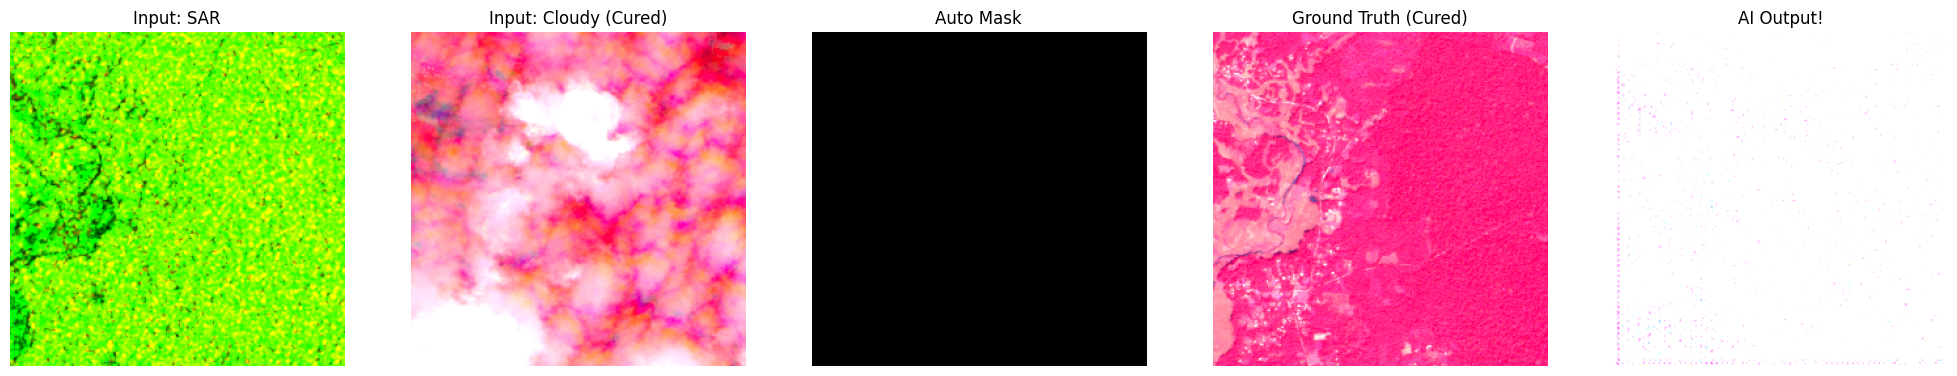

In [49]:
model.eval()
model.to("cpu")

idx = random.randint(0, len(datamodule.val_ds) - 1)
sar_img, cloudy_img, mask, clear_img = datamodule.val_ds[idx]

with torch.no_grad():
    prediction = model(sar_img.unsqueeze(0), cloudy_img.unsqueeze(0), mask.unsqueeze(0))

def to_rgb(tensor_img, is_mask=False):
    img_np = tensor_img.cpu().numpy().transpose(1, 2, 0)
    if is_mask:
        return np.clip(img_np, 0, 1) # Mask is already [0, 1]
    
    # Map [-1, 1] back to [0, 1]
    img_np = (img_np + 1.0) / 2.0
    
    # === DISPLAY BRIGHTNESS BOOST (Gamma Stretch) ===
    # We increase the multiplier to 5.0x AND apply a non-linear Gamma stretch (0.7).
    # This acts like "HDR" for your screen: it powerfully lifts the dark shadows 
    # of the Ground Truth and AI Output so you can see them clearly, without 
    # blowing out the bright clouds in the Input image!
    img_np = np.clip(img_np * 5.0, 0, 1)
    img_np = np.power(img_np, 0.7) 

    
    if img_np.shape[-1] >= 13: # Sentinel-2
        rgb = np.stack([img_np[:, :, 3], img_np[:, :, 2], img_np[:, :, 1]], axis=-1)
        return rgb
    elif img_np.shape[-1] >= 3: # LISS-IV (Green, Red, NIR usually)
        # Standard False Color: NIR -> Red, Red -> Green, Green -> Blue
        # This makes vegetation appear bright red (Industry Standard for LISS-4)
        rgb = np.stack([img_np[:, :, 2], img_np[:, :, 1], img_np[:, :, 0]], axis=-1)
        return rgb
    elif img_np.shape[-1] == 2: # SAR 2-band
        rgb = np.stack([img_np[:, :, 0], img_np[:, :, 1], np.zeros_like(img_np[:, :, 0])], axis=-1)
        return rgb
    return img_np

fig, axes = plt.subplots(1, 5, figsize=(25, 5))
axes[0].set_title("Input: SAR")
axes[0].imshow(to_rgb(sar_img))
axes[1].set_title("Input: Cloudy (Cured)")
axes[1].imshow(to_rgb(cloudy_img))
axes[2].set_title("Auto Mask")
axes[2].imshow(to_rgb(mask, is_mask=True), cmap='gray')
axes[3].set_title("Ground Truth (Cured)")
axes[3].imshow(to_rgb(clear_img))
axes[4].set_title("AI Output!")
axes[4].imshow(to_rgb(prediction[0]))

for ax in axes: ax.axis('off')
plt.show()

In [19]:
# import rasterio

# CUSTOM_SAR = "/kaggle/input/test/sar.tif"
# CUSTOM_CLOUDY = "/kaggle/input/test/cloudy.tif"

# def load_for_inference(path, is_sar=False):
#     with rasterio.open(path) as src:
#         img = src.read()
#         img = img.astype(np.float32)
#         img = np.nan_to_num(img, nan=0.0, posinf=0.0, neginf=0.0)
#         img = np.transpose(img, (1, 2, 0))
    
#     if is_sar:
#         img = 10.0 * np.log10(img + 1e-8) # Linear to dB
    
#     # Simple global normalization (For testing, adjust bounds if needed)
#     img_min, img_max = np.percentile(img, 1.0), np.percentile(img, 99.0)
#     img = np.clip(img, img_min, img_max)
#     img = (img - img_min) / (img_max - img_min + 1e-8) * 2.0 - 1.0
#     return img

# sar_test = load_for_inference(CUSTOM_SAR, is_sar=True)
# cloudy_test = load_for_inference(CUSTOM_CLOUDY, is_sar=False)

# # Auto-mask
# mask_test = (np.mean(cloudy_test, axis=-1, keepdims=True) > 0.4).astype(np.float32)

# transform = A.Compose([
#     A.PadIfNeeded(min_height=None, min_width=None, pad_height_divisor=128, pad_width_divisor=128),
#     ToTensorV2()
# ], additional_targets={'sar': 'image', 'mask': 'image'})

# aug = transform(image=cloudy_test, sar=sar_test, mask=mask_test)
# cloudy_t = aug['image'].unsqueeze(0)
# sar_t = aug['sar'].unsqueeze(0)
# mask_t = aug['mask'].unsqueeze(0)

# # Assuming model is already loaded in memory
# model.eval()
# with torch.no_grad():
#     prediction_t = model(sar_t, cloudy_t, mask_t)

# fig, axes = plt.subplots(1, 2, figsize=(15, 6))
# axes[0].set_title("Input: Cloudy")
# axes[0].imshow(to_rgb(cloudy_t[0]))
# axes[1].set_title("AI Output: Cloud Removed")
# axes[1].imshow(to_rgb(prediction_t[0]))
# plt.show()

In [6]:
# CHECKPOINT_PATH = "/kaggle/input/datasets/paveenpratheek/mmqqwweerr22/sar2opt-multimodal-epoch499.ckpt"
# SAR_DIR = "/kaggle/input/datasets/paveenpratheek/qqwweerr22/SARC"
# OPT_CLOUDY_DIR = "/kaggle/input/datasets/paveenpratheek/qqwweerr22/LISS4C"
# OPT_CLEAR_DIR = "/kaggle/input/datasets/paveenpratheek/qqwweerr22/LISS4NC"

# print("1. Rebuilding DataModule (num_workers=0 prevents freezing)...")
# datamodule = MultiModalDataModule(
#     sar_dir=SAR_DIR, 
#     opt_cloudy_dir=OPT_CLOUDY_DIR, 
#     opt_clear_dir=OPT_CLEAR_DIR, 
#     batch_size=8, 
#     num_workers=0
# )
# datamodule.setup()

# print("2. Rebuilding Model Architecture...")
# sample_sar, sample_cloudy, sample_mask, sample_clear = datamodule.train_ds[0]
# actual_sar_ch = sample_sar.shape[0]
# actual_opt_ch = sample_cloudy.shape[0]

# print(f"Auto-detected SAR Channels: {actual_sar_ch}, Optical Channels: {actual_opt_ch}")
# model = Pix2PixInpaintModule(sar_ch=actual_sar_ch, opt_ch=actual_opt_ch)

# print("3. Resuming Trainer on 1 GPU (Bypassing NCCL bugs)...")

# from pytorch_lightning.callbacks import ModelCheckpoint
# checkpoint_callback = ModelCheckpoint(
#     dirpath="resumed_checkpoints/",
#     filename="sar2opt-resumed-{epoch:03d}",
#     save_top_k=3,
#     monitor="val_loss",
#     mode="min"
# )

# resume_trainer = pl.Trainer(
#     accelerator="gpu",
#     devices=1,                 
#     strategy="auto",   # Forces it to NOT use DDP/NCCL
#     precision="16-mixed",      
#     max_epochs=1200,
#     enable_progress_bar=True,
#     callbacks=[checkpoint_callback] # Automatically saves the new model!
# )

# resume_trainer.fit(model, datamodule, ckpt_path=CHECKPOINT_PATH)

1. Rebuilding DataModule (num_workers=0 prevents freezing)...
2. Rebuilding Model Architecture...
Auto-detected SAR Channels: 2, Optical Channels: 3
Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:04<00:00, 127MB/s]  
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


3. Resuming Trainer on 1 GPU (Bypassing NCCL bugs)...


/usr/local/lib/python3.12/dist-packages/pytorch_lightning/trainer/configuration_validator.py:68: You passed in a `val_dataloader` but have no `validation_step`. Skipping val loop.
Restoring states from the checkpoint path at /kaggle/input/datasets/paveenpratheek/mmqqwweerr22/sar2opt-multimodal-epoch499.ckpt
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/trainer/call.py:283: Be aware that when using `ckpt_path`, callbacks used to create the checkpoint need to be provided during `Trainer` instantiation. Please add the following callbacks: ["ModelCheckpoint{'monitor': None, 'mode': 'min', 'every_n_train_steps': 0, 'every_n_epochs': 50, 'train_time_interval': None}"].
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name          ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ generator     │ GeneratorUNet     │ 29.2 M │ train │     0 │
│ 1 │ discriminator │ Discriminator     │  2.8 M │ train │     0 │
│ 2 │ criterion_gan │ BCEWithLogitsLoss │      0 │ train │     0 │
│ 3 │ vgg_loss      │ VGGLoss           │  3.5 M │ train │     0 │
└───┴───────────────┴───────────────────┴────────┴───────┴───────┘

...

Restored all states from the checkpoint at /kaggle/input/datasets/paveenpratheek/mmqqwweerr22/sar2opt-multimodal-epoch499.ckpt


Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/loops/fit_loop.py:321: The number of training batches (23) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


/usr/local/lib/python3.12/dist-packages/pytorch_lightning/callbacks/model_checkpoint.py:588: 
`ModelCheckpoint(monitor='val_loss')` could not find the monitored key in the returned metrics: ['g_loss', 
'd_loss', 'epoch', 'step']. HINT: Did you call `log('val_loss', value)` in the `LightningModule`?

`Trainer.fit` stopped: `max_epochs=1200` reached.


In [14]:
# # Rescue the model from live memory and save it as a .ckpt file!
# resume_trainer.save_checkpoint("rescued-model-epoch1299.ckpt")

# print("Model successfully rescued and saved to Kaggle output folder!")

`weights_only` was not set, defaulting to `False`.


Model successfully rescued and saved to Kaggle output folder!


Loading Model from Checkpoint...
Testing on Image #0
Running AI Prediction...


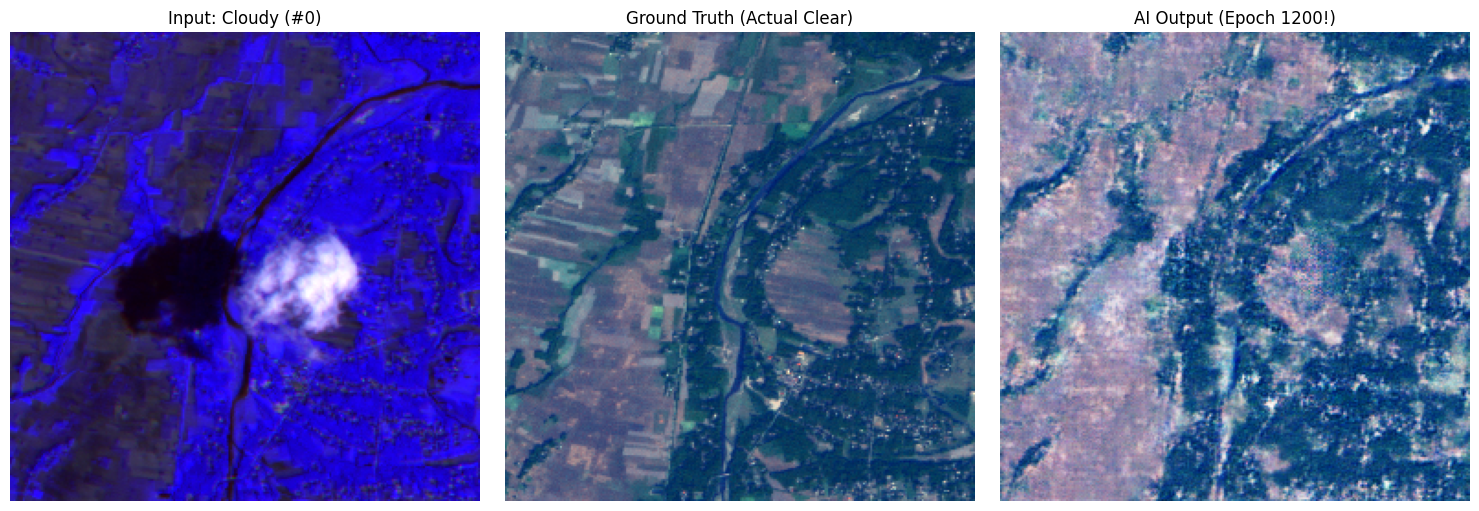

In [21]:
# import torch
# import numpy as np
# import matplotlib.pyplot as plt
# import random

# # 1. Load the AI Brain from your rescued file!
# print("Loading Model from Checkpoint...")
# model = Pix2PixInpaintModule.load_from_checkpoint("rescued-model-epoch1199.ckpt")
# model.eval() 

# if torch.cuda.is_available():
#     model = model.cuda()

# # 2. Grab a COMPLETELY RANDOM test sample
# # Find out exactly how many images we have, and pick a random number!
# max_index = len(datamodule.val_ds) - 1
# random_idx = random.randint(0, max_index)
# print(f"Testing on Image #{random_idx}")

# sar_tensor, cloudy_tensor, mask_tensor, clear_tensor = datamodule.val_ds[random_idx] 

# sar_input = sar_tensor.unsqueeze(0).to(model.device)
# cloudy_input = cloudy_tensor.unsqueeze(0).to(model.device)
# mask_input = mask_tensor.unsqueeze(0).to(model.device)

# # 3. RUN THE INFERENCE
# print("Running AI Prediction...")
# with torch.no_grad(): 
#     ai_prediction = model(sar_input, cloudy_input, mask_input)

# # 4. Process the Output back into a visible picture
# def tensor_to_image(tensor):
#     img = tensor.squeeze().cpu().numpy()     
#     img = np.transpose(img, (1, 2, 0))       
#     img = (img + 1.0) / 2.0                  
#     return np.clip(img, 0, 1)                

# final_image = tensor_to_image(ai_prediction)
# truth_image = tensor_to_image(clear_tensor)
# cloudy_image = tensor_to_image(cloudy_tensor) 

# # 5. Plot the final result with all 3 images!
# plt.figure(figsize=(15, 5)) 

# plt.subplot(1, 3, 1)
# plt.title(f"Input: Cloudy (#{random_idx})")
# plt.imshow(cloudy_image)
# plt.axis("off")

# plt.subplot(1, 3, 2)
# plt.title("Ground Truth (Actual Clear)")
# plt.imshow(truth_image)
# plt.axis("off")

# plt.subplot(1, 3, 3)
# plt.title("AI Output (Epoch 1200!)")
# plt.imshow(final_image)
# plt.axis("off")

# plt.tight_layout()
# plt.show()